# ESOL solubility: ESOL equation vs linear and random forest models

Compares the published ESOL equation with a refitted linear model, and three random forests
(Delaney descriptors, Morgan fingerprints, both). on random and scaffold splits,
repeated over several seeds. Models get trained on random and scaffold splits, and this is repeated over 10 (by default) seeds.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score
from time import perf_counter
from collections import defaultdict

N_SEEDS = 10                                                            # number of repeated splits

## Data

In [2]:
df = pd.read_csv("data/delaney-processed.csv")

smiles_array = df["smiles"].str.strip().to_numpy()
molecules = [Chem.MolFromSmiles(s) for s in smiles_array]
scaffolds = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in molecules])

y = df["measured log solubility in mols per litre"].to_numpy()

esol_predicted = df["ESOL predicted log solubility in mols per litre"].to_numpy()

## Features

`features.py`: Morgan fingerprints (radius 2, 2048 bits) and the 4 descriptors used by Delaney in the ESOL equation (not all descriptors found in the dataset are used, since Delaney found these to be less important* so I left them out for consistency).

*under METHOD in Delaney's paper

In [3]:
from features import descriptor_functions, featurise, featurise_descriptors_only

X_fp = featurise(molecules)
X_desc = featurise_descriptors_only(molecules, descriptor_functions)

## Splits

`scaffold_split` groups molecules by Murcko scaffold, then fills the training set to 80% and puts the rest into the test set.
When there is no seed, groups are taken largest first meaning the split is always the same. However, when given a seed, groups bigger than half the training set size will always be put in training while other groups are shuffled.

In [4]:
def scaffold_split(scaffolds, test_size=0.2, seed=None):
    groups = defaultdict(list)
    for i, scaffold in enumerate(scaffolds):
        groups[scaffold].append(i)

    sorted_groups = sorted(groups.values(), key=len, reverse=True)

    if seed is not None:                                                # randomised 
        big_cutoff = len(scaffolds) * test_size / 2                     # groups bigger than half the test set are always trained on
        big_groups = [g for g in sorted_groups if len(g) > big_cutoff]
        small_groups = [g for g in sorted_groups if len(g) <= big_cutoff]
        rng = np.random.default_rng(seed)
        rng.shuffle(small_groups)
        sorted_groups = big_groups + small_groups

    train_rows = []
    test_rows = []
    train_size = len(scaffolds) * (1 - test_size)

    for group in sorted_groups:
        if len(train_rows) + len(test_rows) <= train_size:
            train_rows.extend(group)
        else:
            test_rows.extend(group)

    return np.array(train_rows), np.array(test_rows)

## Models

In [5]:
def make_experiments(X_fp_train, X_fp_test, X_desc_train, X_desc_test, seed=42):

    X_both_train = np.hstack((X_fp_train, X_desc_train))
    X_both_test = np.hstack((X_fp_test, X_desc_test))

    experiments = {
        "Linear"        :     (LinearRegression(), X_desc_train, X_desc_test),
        "RF descriptors":     (RandomForestRegressor(n_estimators=500, random_state=seed, n_jobs=-1), X_desc_train, X_desc_test),
        "RF fingerprint":     (RandomForestRegressor(n_estimators=500, random_state=seed, n_jobs=-1), X_fp_train, X_fp_test),
        "RF both"       :     (RandomForestRegressor(n_estimators=500, random_state=seed, n_jobs=-1), X_both_train, X_both_test)}
    return experiments

def run_experiments(experiments, y_train, y_test, esol_pred_test):
    results = []
    trained_models = {}

    for name, (model, X_train, X_test) in experiments.items():
        start_time = perf_counter()
        model.fit(X_train, y_train)
        train_time = perf_counter() - start_time

        predictions = model.predict(X_test)
        results.append( {
            "model": name,
            "rmse" : root_mean_squared_error(y_test, predictions),
            "r2"   : r2_score(y_test, predictions),
            "time" : train_time})
        trained_models[name] = model

    results.insert(0, {
        "model": "ESOL equation (baseline)",
        "rmse" : root_mean_squared_error(y_test, esol_pred_test),
        "r2"   : r2_score(y_test, esol_pred_test)})

    return results, trained_models

## Run

10 seeds × 2 splits × 3 random forests. The seed-0 models are kept for the parity plots.

In [6]:
all_results = []
seed0_models = {}                                                       # split name -> (trained models, test rows), for parity plots

for seed in range(N_SEEDS):
    splits = {
        "random"  : train_test_split(np.arange(len(y)), test_size=0.2, random_state=seed),
        "scaffold": scaffold_split(scaffolds, seed=seed)}

    for split_name, (train_rows, test_rows) in splits.items():
        experiments = make_experiments(X_fp[train_rows], X_fp[test_rows], X_desc[train_rows], X_desc[test_rows], seed=seed)
        results, models = run_experiments(experiments, y[train_rows], y[test_rows], esol_predicted[test_rows])
        for row in results:
            row["split"] = split_name
            row["seed"] = seed
        all_results.extend(results)
        if seed == 0:
            seed0_models[split_name] = (models, test_rows)
    print(f"seed {seed} done")

results_df = pd.DataFrame(all_results)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done


## Summary tables

In [7]:
model_order = ["ESOL equation (baseline)", "Linear", "RF descriptors", "RF fingerprint", "RF both"]

summary = (results_df.groupby(["split", "model"])[["rmse", "r2"]]
           .agg(["mean", "std"])
           .reindex(model_order, level="model")
           .round(3))
summary

rmse            r2       
                                    mean    std   mean    std
split    model                                               
random   ESOL equation (baseline)  0.889  0.059  0.820  0.026
         Linear                    0.989  0.052  0.777  0.029
         RF descriptors            0.691  0.044  0.891  0.014
         RF fingerprint            0.908  0.057  0.812  0.025
         RF both                   0.645  0.048  0.905  0.014
scaffold ESOL equation (baseline)  0.987  0.062  0.781  0.039
         Linear                    1.089  0.069  0.729  0.071
         RF descriptors            0.950  0.089  0.798  0.036
         RF fingerprint            1.349  0.207  0.599  0.073
         RF both                   0.910  0.069  0.815  0.027

In [8]:
rmse_table = results_df.pivot_table(index=["split", "seed"], columns="model", values="rmse")
vs_esol = rmse_table.sub(rmse_table["ESOL equation (baseline)"], axis=0).drop(columns="ESOL equation (baseline)")
vs_esol.groupby("split").agg(["mean", "std"]).round(3)

model    Linear        RF both        RF descriptors        RF fingerprint  \
           mean    std    mean    std           mean    std           mean   
split                                                                        
random    0.100  0.032  -0.244  0.055         -0.198  0.061          0.019   
scaffold  0.102  0.059  -0.077  0.049         -0.037  0.073          0.362   

model            
            std  
split            
random    0.082  
scaffold  0.199

## Plots

In [9]:
SPLIT_COLOURS = {"random": "#2ad64f", "scaffold": "#cd34eb"}
SPLIT_LABELS = {"random": "Random split", "scaffold": "Scaffold split"}
NORMAL, FAINT, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": GRID,
    "axes.labelcolor": FAINT,
    "axes.titlecolor": NORMAL,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": FAINT,
    "ytick.color": FAINT,
    "legend.frameon": False,
})

def model_dot_plot(ax, table, models, xlabel):

    offsets = {"random": -0.15, "scaffold": 0.15}
    for split, offset in offsets.items():
        values = table.loc[split]
        for i, model in enumerate(models):
            ypos = i + offset
            ax.scatter(values[model], np.full(len(values), ypos), s=14,
                       color=SPLIT_COLOURS[split], alpha=0.35, linewidths=0, zorder=2)
            ax.errorbar(values[model].mean(), ypos, xerr=values[model].std(), fmt="o", ms=7,
                        color=SPLIT_COLOURS[split], mec="white", mew=1.5, elinewidth=2,
                        capsize=0, zorder=3, label=SPLIT_LABELS[split] if i == 0 else None)
    ax.set_yticks(range(len(models)), [m.replace(" (baseline)", "") for m in models])
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0, labelcolor=NORMAL)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.legend(loc="upper right")

### RMSE by model and split

Faint dots are individual seeds. The large dot is the mean and the bars extend to 1 standard deviation.

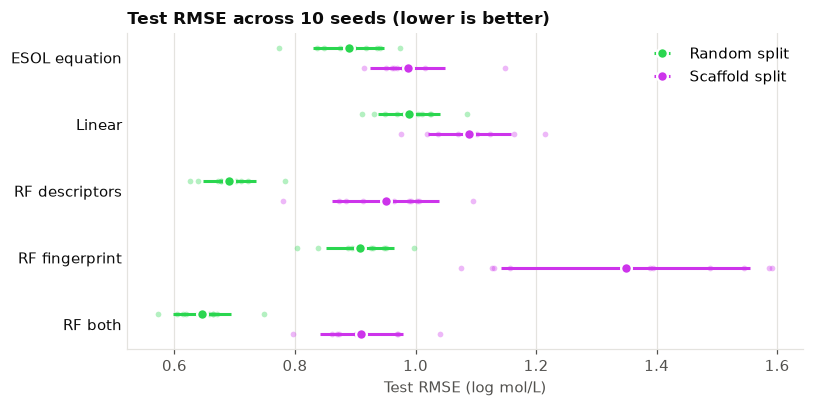

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
model_dot_plot(ax, rmse_table, model_order, "Test RMSE (log mol/L)")
ax.set_title(f"Test RMSE across {N_SEEDS} seeds (lower is better)")
fig.tight_layout()
fig.savefig("figures/rmse_by_model_and_split.png", dpi=200, bbox_inches="tight")
plt.show()

### RMSE relative to ESOL on the same test set

Subtracting ESOL's RMSE on each test set removes the factor of the difficulty of a particular split. This means that if anything is to the left of zero, it performed better than ESOL.

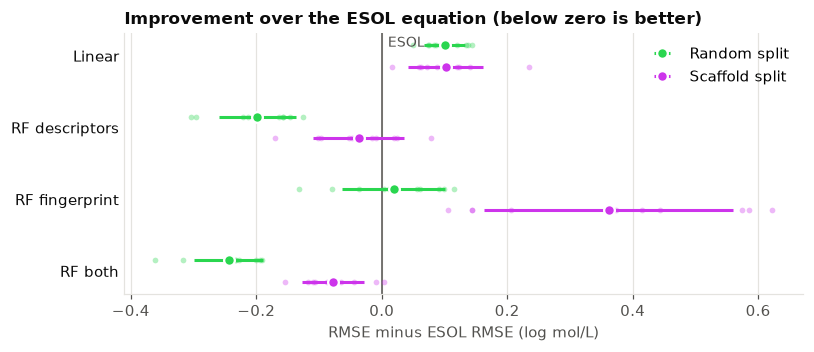

In [11]:
compared = [m for m in model_order if m != "ESOL equation (baseline)"]

fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.axvline(0, color=FAINT, linewidth=1, zorder=1)
ax.annotate("ESOL", xy=(0, 1), xycoords=("data", "axes fraction"), xytext=(4, -2),
            textcoords="offset points", va="top", color=FAINT, fontsize=9)
model_dot_plot(ax, vs_esol, compared, "RMSE minus ESOL RMSE (log mol/L)")
ax.set_title("Improvement over the ESOL equation (below zero is better)")
fig.tight_layout()
fig.savefig("figures/RMSE_Relative_ESOL", dpi=200, bbox_inches="tight")
plt.show()

### Parity plots (seed=0)

Predicted against measured log solubility for the ESOL equation and RF both. The diagonal is perfect prediction (the prediction = measureed value)

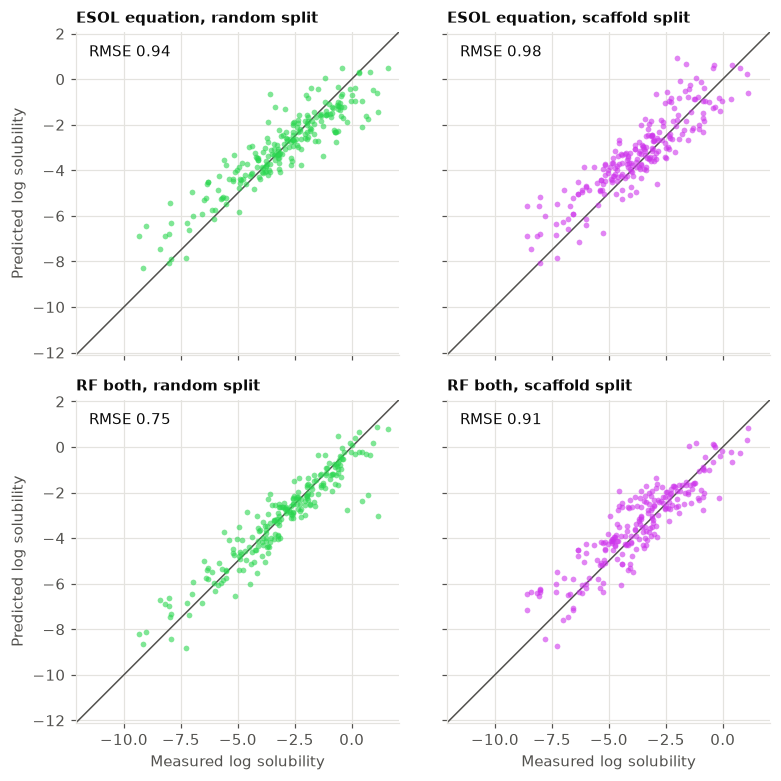

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7.2), sharex=True, sharey=True)
lims = (y.min() - 0.5, y.max() + 0.5)

for col, split in enumerate(["random", "scaffold"]):
    models, test_rows = seed0_models[split]
    X_both_test = np.hstack((X_fp[test_rows], X_desc[test_rows]))
    predictions = {
        "ESOL equation": esol_predicted[test_rows],
        "RF both": models["RF both"].predict(X_both_test)}

    for row, (name, pred) in enumerate(predictions.items()):
        ax = axes[row, col]
        ax.plot(lims, lims, color=FAINT, linewidth=1, zorder=1)
        ax.scatter(y[test_rows], pred, s=14, color=SPLIT_COLOURS[split], alpha=0.6,
                   linewidths=0, zorder=2)
        rmse = root_mean_squared_error(y[test_rows], pred)
        ax.text(0.04, 0.96, f"RMSE {rmse:.2f}", transform=ax.transAxes, va="top", color=NORMAL)
        ax.set_title(f"{name}, {SPLIT_LABELS[split].lower()}", fontsize=10)
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_aspect("equal")
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)

for ax in axes[1, :]:
    ax.set_xlabel("Measured log solubility")
for ax in axes[:, 0]:
    ax.set_ylabel("Predicted log solubility")
fig.tight_layout()
fig.savefig("figures/Parity", dpi=200, bbox_inches="tight")
plt.show()